# 04 · Ranking de segmentos para o piloto

**Projeto:** Apex Imóveis — priorização de segmentos residenciais para um piloto de prospecção.

**Pergunta central do contrato:** quais segmentos de apartamentos apresentam atividade transacional recorrente e preços de referência confiáveis, mesmo depois de corrigir inflação e composição?

**Segmento** = setor fiscal × faixa de área construída.

**Neste notebook:**
1. Descrevemos os segmentos e como a atividade se distribui entre eles.
2. Aplicamos **critérios transparentes** (volume, recorrência, comparabilidade, estabilidade), sem score com pesos arbitrários.
3. Testamos se a lista **resiste** a critérios mais rígidos ou mais frouxos.
4. Montamos o ranking dos elegíveis para o piloto.

> **[NOTEBOOK]** porque estamos explorando e calibrando critérios.

**O que o ranking mede:** atividade transacional **observada**. Não é liquidez (não há estoque como denominador) nem receita da Apex.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_colwidth", None)
candidatos = [Path.cwd(), *Path.cwd().parents]
raiz = next((p for p in candidatos if (p / "src" / "database.py").exists()), None)
assert raiz is not None, f"Não achei src/database.py a partir de {Path.cwd()}. O notebook está dentro de apex-imoveis?"
sys.path.append(str(raiz / "src"))

from database import get_engine

engine = get_engine()


def consulta(sql: str) -> pd.DataFrame:
    return pd.read_sql(sql, engine)


def milhar(n) -> str:
    return f"{n:,.0f}".replace(",", ".")

## 1. Carregar o recorte

Mesma janela de análise (jan/2022 a nov/2025). Criamos as colunas que os critérios precisam: faixa de área, trimestre e **metade** da janela (2022–23 contra 2024–25).

In [2]:
df = consulta("""
    SELECT data_transacao, mes_transacao, setor_fiscal, area_construida, preco_m2_real, valor_real
    FROM analytics.vw_apto_recorte
    WHERE na_janela_analise AND NOT sem_deflator
""")

df["data_transacao"] = pd.to_datetime(df["data_transacao"])
df["mes_transacao"] = pd.to_datetime(df["mes_transacao"])
for col in ["area_construida", "preco_m2_real", "valor_real"]:
    df[col] = df[col].astype(float)

df["faixa_area"] = pd.cut(
    df["area_construida"],
    bins=[0, 50, 80, 120, 200, np.inf],
    labels=["até 50", "50–80", "80–120", "120–200", "acima de 200"],
).astype(str)
df["trimestre"] = df["data_transacao"].dt.to_period("Q").astype(str)
df["metade"] = np.where(df["mes_transacao"] < "2024-01-01", "2022-23", "2024-25")

print(f"{milhar(len(df))} transações | {df['setor_fiscal'].nunique()} setores | "
      f"{df['trimestre'].nunique()} trimestres | metades: {sorted(df['metade'].unique())}")
df[["setor_fiscal", "faixa_area", "trimestre", "metade"]].head(3)

222.295 transações | 236 setores | 16 trimestres | metades: ['2022-23', '2024-25']


,setor_fiscal,faixa_area,trimestre,metade
0,176,50–80,2023Q1,2022-23
1,020,50–80,2023Q1,2022-23
2,006,até 50,2023Q1,2022-23


## 2. Os segmentos e como a atividade se distribui

Para cada segmento, calculamos: número de transações, mediana do R$/m² real, **dispersão** (amplitude interquartil relativa: quanto menor, mais homogêneo), ticket mediano, transações em cada metade, variação da mediana entre as metades e **trimestres ativos** (com 5 ou mais transações).

In [3]:
chave = ["setor_fiscal", "faixa_area"]
g = df.groupby(chave)

seg = pd.DataFrame({
    "transacoes": g.size(),
    "preco_mediano": g["preco_m2_real"].median(),
    "dispersao": (g["preco_m2_real"].quantile(0.75) - g["preco_m2_real"].quantile(0.25))
                 / g["preco_m2_real"].median(),
    "ticket_mediano": g["valor_real"].median(),
})

por_metade = (
    df.groupby(chave + ["metade"])
    .agg(n=("preco_m2_real", "size"), mediana=("preco_m2_real", "median"))
    .unstack("metade")
)
seg["n_2022_23"] = por_metade[("n", "2022-23")]
seg["n_2024_25"] = por_metade[("n", "2024-25")]
seg[["n_2022_23", "n_2024_25"]] = seg[["n_2022_23", "n_2024_25"]].fillna(0)
seg["var_metades"] = (por_metade[("mediana", "2024-25")] / por_metade[("mediana", "2022-23")] - 1) * 100

por_trimestre = df.groupby(chave + ["trimestre"]).size().unstack(fill_value=0)
seg["trimestres_ativos"] = (por_trimestre >= 5).sum(axis=1)      # trimestres com 5 ou mais transações

seg = seg.reset_index()
possiveis = df["setor_fiscal"].nunique() * df["faixa_area"].nunique()
print(f"{len(seg)} segmentos com ao menos 1 transação (de {possiveis} possíveis)")
seg["transacoes"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(0).map(milhar)

949 segmentos com ao menos 1 transação (de 1180 possíveis)


count      949
mean       234
std        286
min          1
10%          7
25%         27
50%        125
75%        338
90%        613
max      1.698
Name: transacoes, dtype: object

os 50 maiores segmentos concentram 25% das transações
os 100 maiores segmentos concentram 40% das transações
os 200 maiores segmentos concentram 62% das transações
139 segmentos somam metade das transações


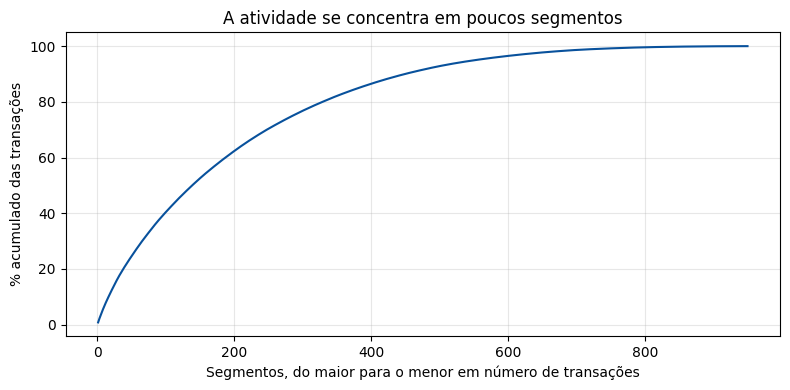

In [4]:
ordenado = seg.sort_values("transacoes", ascending=False).reset_index(drop=True)
acumulado = ordenado["transacoes"].cumsum() / ordenado["transacoes"].sum() * 100

for k in (50, 100, 200):
    print(f"os {k} maiores segmentos concentram {acumulado.iloc[k - 1]:.0f}% das transações")
print(f"{int((acumulado < 50).sum()) + 1} segmentos somam metade das transações")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(acumulado) + 1), acumulado, color="#08519C")
ax.set_xlabel("Segmentos, do maior para o menor em número de transações")
ax.set_ylabel("% acumulado das transações")
ax.set_title("A atividade se concentra em poucos segmentos")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Critérios de elegibilidade

Quatro critérios, todos com parâmetros no topo da célula seguinte:

1. **Volume:** ao menos `MIN_POR_METADE` transações em **cada** metade da janela.
2. **Recorrência:** ao menos 5 transações em `MIN_TRIM_ATIVOS` dos 16 trimestres.
3. **Comparabilidade:** dispersão (amplitude interquartil relativa) de no máximo `LIMITE_DISPERSAO`.
4. **Estabilidade:** variação da mediana real entre as metades de no máximo `LIMITE_VARIACAO`.

Mostramos quantos segmentos passam em cada critério **sozinho** e **em sequência** (acumulado).

In [5]:
MIN_POR_METADE = 50        
MIN_TRIM_ATIVOS = 14       
LIMITE_DISPERSAO = 0.50    
LIMITE_VARIACAO = 10.0    

criterios = {
    f"volume: ≥ {MIN_POR_METADE} em cada metade":
        (seg["n_2022_23"] >= MIN_POR_METADE) & (seg["n_2024_25"] >= MIN_POR_METADE),
    f"recorrência: ≥ {MIN_TRIM_ATIVOS} de 16 trimestres ativos":
        seg["trimestres_ativos"] >= MIN_TRIM_ATIVOS,
    f"comparabilidade: dispersão ≤ {LIMITE_DISPERSAO}":
        seg["dispersao"] <= LIMITE_DISPERSAO,
    f"estabilidade: |variação entre metades| ≤ {LIMITE_VARIACAO:.0f}%":
        seg["var_metades"].abs() <= LIMITE_VARIACAO,
}

passa = pd.Series(True, index=seg.index)
linhas = [("todos os segmentos", len(seg), len(seg), int(seg["transacoes"].sum()))]
for nome, condicao in criterios.items():
    passa &= condicao
    linhas.append((nome, int(condicao.sum()), int(passa.sum()), int(seg.loc[passa, "transacoes"].sum())))

funil_seg = pd.DataFrame(linhas, columns=["critério", "passam sozinhos", "restantes (acumulado)", "transações"])
funil_seg["% das transações"] = funil_seg["transações"] / seg["transacoes"].sum() * 100
seg["elegivel"] = passa

vista = funil_seg.copy()
for col in ["passam sozinhos", "restantes (acumulado)", "transações"]:
    vista[col] = vista[col].map(milhar)
vista["% das transações"] = vista["% das transações"].map(lambda x: f"{x:.1f}%")
vista

,critério,passam sozinhos,restantes (acumulado),transações,% das transações
0,todos os segmentos,949,949,222.295,100.0%
1,volume: ≥ 50 em cada metade,475,475,202.598,91.1%
2,recorrência: ≥ 14 de 16 trimestres ativos,464,458,199.481,89.7%
3,comparabilidade: dispersão ≤ 0.5,802,390,168.043,75.6%
4,estabilidade: |variação entre metades| ≤ 10%,641,355,155.526,70.0%


## 4. A lista resiste a critérios diferentes?

Os limites são decisões de julgamento. Refazemos a lista com limites **mais rígidos** e **mais frouxos**, e também mexendo em **um critério de cada vez**, para ver quanto da lista do caso base permanece.

Os segmentos que continuam elegíveis mesmo no cenário mais rígido formam um **núcleo robusto**.

In [6]:
def elegiveis(min_metade, min_trim, disp, var):
    return (
        (seg["n_2022_23"] >= min_metade) & (seg["n_2024_25"] >= min_metade)
        & (seg["trimestres_ativos"] >= min_trim)
        & (seg["dispersao"] <= disp)
        & (seg["var_metades"].abs() <= var)
    )


base = seg["elegivel"]
cenarios = {
    "caso base": (MIN_POR_METADE, MIN_TRIM_ATIVOS, LIMITE_DISPERSAO, LIMITE_VARIACAO),
    "mais rígido (tudo)": (100, 15, 0.40, 7.5),
    "mais frouxo (tudo)": (30, 12, 0.60, 15.0),
    "só volume mais rígido (100)": (100, MIN_TRIM_ATIVOS, LIMITE_DISPERSAO, LIMITE_VARIACAO),
    "só recorrência mais rígida (16)": (MIN_POR_METADE, 16, LIMITE_DISPERSAO, LIMITE_VARIACAO),
    "só dispersão mais rígida (0,40)": (MIN_POR_METADE, MIN_TRIM_ATIVOS, 0.40, LIMITE_VARIACAO),
    "só estabilidade mais rígida (5%)": (MIN_POR_METADE, MIN_TRIM_ATIVOS, LIMITE_DISPERSAO, 5.0),
}

linhas = []
for nome, parametros in cenarios.items():
    lista = elegiveis(*parametros)
    linhas.append({
        "cenário": nome,
        "segmentos": int(lista.sum()),
        "% das transações": seg.loc[lista, "transacoes"].sum() / seg["transacoes"].sum() * 100,
        "% do caso base que permanece": (lista & base).sum() / base.sum() * 100,
    })
sens_lista = pd.DataFrame(linhas)
seg["elegivel_rigido"] = elegiveis(*cenarios["mais rígido (tudo)"])  

vista = sens_lista.copy()
vista["% das transações"] = vista["% das transações"].map(lambda x: f"{x:.1f}%")
vista["% do caso base que permanece"] = vista["% do caso base que permanece"].map(lambda x: f"{x:.0f}%")
vista

,cenário,segmentos,% das transações,% do caso base que permanece
0,caso base,355,70.0%,100%
1,mais rígido (tudo),174,40.4%,49%
2,mais frouxo (tudo),442,81.9%,100%
3,só volume mais rígido (100),263,62.9%,74%
4,só recorrência mais rígida (16),300,65.6%,85%
5,"só dispersão mais rígida (0,40)",266,49.1%,75%
6,só estabilidade mais rígida (5%),272,55.8%,77%


## 5. Ranking para o piloto

Entre os elegíveis, ordenamos pela **atividade observada** (transações no período). Cada segmento recebe também contexto: preço mediano, dispersão, ticket mediano, variação do preço entre as metades, tendência da atividade e se pertence ao **núcleo robusto**.

`N_PILOTO` representa a **capacidade fictícia** da equipe de prospecção. Mude-a se quiser outro tamanho de piloto.

> Lembrete: atividade observada **não é** liquidez (sem estoque como denominador), nem receita da Apex.

In [7]:
rotulos = consulta("SELECT setor_fiscal, ruas_mais_frequentes FROM analytics.dim_setor_fiscal")

meses = df.groupby("metade")["mes_transacao"].nunique()      
ranking = seg[seg["elegivel"]].copy()
ranking["transacoes_por_trimestre"] = ranking["transacoes"] / df["trimestre"].nunique()
ranking["tendencia_atividade"] = (
    (ranking["n_2024_25"] / meses["2024-25"]) / (ranking["n_2022_23"] / meses["2022-23"]) - 1
) * 100
ranking = (
    ranking.merge(rotulos, on="setor_fiscal", how="left")
    .sort_values("transacoes", ascending=False)
    .reset_index(drop=True)
)
ranking["ruas_mais_frequentes"] = ranking["ruas_mais_frequentes"].fillna("")
ranking["robusto"] = np.where(ranking["elegivel_rigido"], "sim", "não")

N_PILOTO = 20      
piloto = ranking.head(N_PILOTO)
print(f"{len(ranking)} segmentos elegíveis; os {N_PILOTO} maiores concentram "
      f"{piloto['transacoes'].sum() / ranking['transacoes'].sum() * 100:.0f}% da atividade dos elegíveis "
      f"e {piloto['transacoes'].sum() / seg['transacoes'].sum() * 100:.0f}% da atividade total do recorte")
print(f"destes {N_PILOTO}, {(piloto['robusto'] == 'sim').sum()} também passam nos critérios mais rígidos")

vista = piloto[["setor_fiscal", "faixa_area", "ruas_mais_frequentes", "transacoes_por_trimestre",
                "preco_mediano", "dispersao", "ticket_mediano", "var_metades", "tendencia_atividade", "robusto"]].copy()
vista["transacoes_por_trimestre"] = vista["transacoes_por_trimestre"].map(milhar)
vista["preco_mediano"] = vista["preco_mediano"].map(milhar)
vista["ticket_mediano"] = vista["ticket_mediano"].map(milhar)
vista["dispersao"] = vista["dispersao"].map(lambda x: f"{x:.2f}")
vista["var_metades"] = vista["var_metades"].map(lambda x: f"{x:+.1f}%")
vista["tendencia_atividade"] = vista["tendencia_atividade"].map(lambda x: f"{x:+.0f}%")
vista

355 segmentos elegíveis; os 20 maiores concentram 16% da atividade dos elegíveis e 11% da atividade total do recorte
destes 20, 10 também passam nos critérios mais rígidos


,setor_fiscal,faixa_area,ruas_mais_frequentes,transacoes_por_trimestre,preco_mediano,dispersao,ticket_mediano,var_metades,tendencia_atividade,robusto
0,078,80–120,AV RAIMUNDO PEREIRA DE MAGALHAES / AV APARECIDA DO RIO NEGRO / R WILLIS ROBERTO BANKS,106,3.648,0.30,340.342,-1.0%,+40%,sim
1,171,120–200,R DR LUIZ MIGLIANO / R FRANCISCO JOSE DA SILVA / R JOSE DA SILVA RIBEIRO,106,3.887,0.48,600.365,-3.6%,-5%,não
2,169,80–120,R JARACATIA / R CELSO RAMOS / R CARVALHO DE FREITAS,95,3.590,0.31,323.845,+3.9%,+3%,sim
3,047,80–120,AV FAGUNDES FILHO / R DOS DEMOCRATAS / AV JABAQUARA,91,5.048,0.30,507.374,+3.8%,+47%,sim
4,085,120–200,R JOAO DE LACERDA SOARES / R MICHIGAN / R NOVA YORK,90,7.144,0.44,1.126.260,+3.6%,+32%,não
5,062,80–120,R TUIUTI / R ARNALDO CINTRA / R IVAI,84,4.471,0.44,452.111,-5.5%,-3%,não
6,157,80–120,AV DOS OURIVES / R PROF ARNALDO JOAO SEMERARO / AV DO CURSINO,84,2.917,0.33,280.164,-3.2%,+11%,sim
7,085,80–120,R JOAO DE LACERDA SOARES / R MICHIGAN / R NOVA YORK,83,7.158,0.35,715.137,+2.3%,+49%,sim
8,007,até 50,AV S JOAO / R REGO FREITAS / PC DA REPUBLICA,79,6.536,0.41,246.813,+3.7%,+73%,não
9,090,120–200,AV SARG GERALDO SANT'ANA / R DAS FLECHAS / AV INTERLAGOS,78,4.119,0.41,598.576,+0.4%,+4%,não


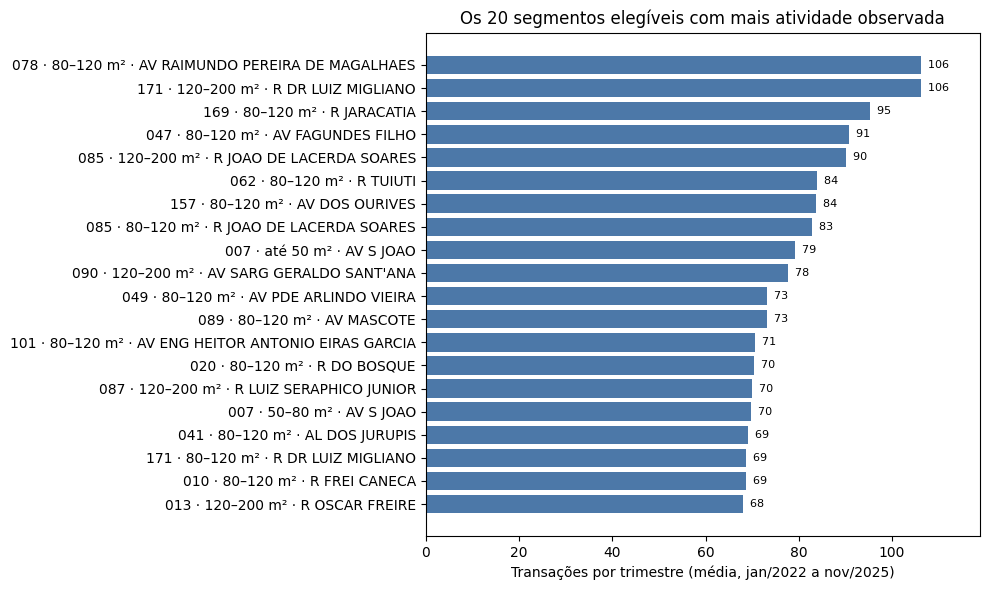

In [8]:
nomes = (piloto["setor_fiscal"] + " · " + piloto["faixa_area"] + " m² · "
         + piloto["ruas_mais_frequentes"].str.split(" / ").str[0])

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(nomes, piloto["transacoes_por_trimestre"], color="#4C78A8")
ax.invert_yaxis()
for i, v in enumerate(piloto["transacoes_por_trimestre"]):
    ax.text(v, i, f"  {v:.0f}", va="center", fontsize=8)
ax.set_xlim(0, piloto["transacoes_por_trimestre"].max() * 1.12)
ax.set_xlabel("Transações por trimestre (média, jan/2022 a nov/2025)")
ax.set_title(f"Os {N_PILOTO} segmentos elegíveis com mais atividade observada")
plt.tight_layout()
plt.show()

## 6. Gravar os resultados no banco

Gravamos os segmentos (com critérios, núcleo robusto e posição no ranking), o funil dos critérios e a sensibilidade em tabelas do esquema `analytics`, para o Power BI ler. São apenas **agregados**, sem identificação de imóveis.

In [10]:
posicoes = ranking[["setor_fiscal", "faixa_area"]].copy()
posicoes["posicao_ranking"] = range(1, len(posicoes) + 1)

res_seg = (
    seg.merge(rotulos, on="setor_fiscal", how="left")
    .merge(posicoes, on=["setor_fiscal", "faixa_area"], how="left")
)
res_seg["posicao_ranking"] = res_seg["posicao_ranking"].astype("Int64")

res_seg["segmento"] = res_seg["setor_fiscal"] + " · " + res_seg["faixa_area"] + " m²"
res_seg["faixa_ordem"] = res_seg["faixa_area"].map({"até 50": 1, "50–80": 2, "80–120": 3, "120–200": 4, "acima de 200": 5})
res_seg["rua_referencia"] = res_seg["ruas_mais_frequentes"].fillna("").str.split(" / ").str[0]
res_seg["transacoes_por_trimestre"] = res_seg["transacoes"] / df["trimestre"].nunique()
res_seg["tendencia_atividade"] = (
    (res_seg["n_2024_25"] / meses["2024-25"]) / (res_seg["n_2022_23"] / meses["2022-23"]) - 1
) * 100
res_seg["tendencia_atividade"] = res_seg["tendencia_atividade"].replace([np.inf, -np.inf], np.nan)

ordem = res_seg["posicao_ranking"].fillna(10**6).astype(int)     # sem posição = fora do ranking
res_seg["grupo"] = np.select(
    [
        res_seg["elegivel_rigido"] & (ordem <= N_PILOTO),
        res_seg["elegivel"] & (ordem <= N_PILOTO),
        res_seg["elegivel"],
    ],
    ["Recomendado", "A validar", "Elegível, fora do top"],
    default="Não elegível",
)

res_funil = funil_seg.rename(columns={
    "critério": "criterio",
    "passam sozinhos": "passam_sozinhos",
    "restantes (acumulado)": "restantes_acumulado",
    "transações": "transacoes",
    "% das transações": "pct_transacoes",
})
res_funil.insert(0, "etapa", range(len(res_funil)))

res_cenarios = sens_lista.rename(columns={
    "cenário": "cenario",
    "% das transações": "pct_transacoes",
    "% do caso base que permanece": "pct_caso_base_que_permanece",
})

agora = pd.Timestamp.now().floor("s")
resultados = {"res_segmentos": res_seg, "res_funil_segmentos": res_funil, "res_cenarios_elegiveis": res_cenarios}
for nome, tabela in resultados.items():
    tabela["gerado_em"] = agora
    tabela.to_sql(nome, engine, schema="analytics", if_exists="replace", index=False)
    print(f"analytics.{nome}: {len(tabela)} linhas")

analytics.res_segmentos: 949 linhas
analytics.res_funil_segmentos: 5 linhas
analytics.res_cenarios_elegiveis: 7 linhas
